<a href="https://colab.research.google.com/github/DS-3001-Group-15/L03-tree-stability/blob/main/L3_notebook_complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**AI-use disclosure for this combined working copy:** Questions 1–3 are preserved from the linked GitHub notebook. Questions 4–6 were added with AI assistance. Therefore, this combined notebook should **not** be represented as a Phase 1 solution completed without generative AI. Follow the course rules for Phase 1 versus Phase 2 when submitting.

**Student(s):** Charlotte Olexy, Maya Yonathan, Mouad Tazka

**Date of original notebook:** 11/17/2026

In [15]:
# Your Phase 1 solution to the problem goes here.

import pandas as pd
import numpy as np

heart = pd.read_csv("../../../../Downloads/heart_failure_clinical_records_dataset.csv")

heart.head(5)

FileNotFoundError: [Errno 2] No such file or directory: '../../../../Downloads/heart_failure_clinical_records_dataset.csv'

In [17]:
#drop any na values and clean the Age variable
heart.dropna()

heart["age"] = np.floor(heart["age"])

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression

heart_no_target = heart.drop(columns = "DEATH_EVENT")

X = heart_no_target
y = heart["DEATH_EVENT"]

seeds = [42, 101, 123, 456]
results = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    tree = DecisionTreeClassifier(random_state=seed)
    tree.fit(X_train, y_train)

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    tree_predictions = tree.predict(X_test)
    linear_predictions = linear_model.predict(X_test)

    results.append({
        "seed": seed,
        "tree": tree,
        "linear model": linear_model,
        "tree prediction": tree_predictions,
        "linear prediction": linear_predictions
        })

print(results)

[{'seed': 42, 'tree': DecisionTreeClassifier(random_state=42), 'linear model': LinearRegression(), 'tree prediction': array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1]), 'linear prediction': array([ 1.59253109e-01, -1.49250611e-01,  2.60210853e-01,  1.57809193e+00,
        2.70519005e-01,  9.22297065e-03,  5.30345820e-01,  2.77933803e-01,
        8.35339211e-01,  2.23000344e-01,  2.82241720e-01,  1.52357167e-01,
        2.34135496e-01,  3.34484236e-01,  3.59330278e-01,  5.40661659e-01,
        1.07127451e-01,  4.01724635e-01,  2.80515761e-01,  4.30053077e-01,
        4.40099556e-01,  3.83372551e-01,  2.89713414e-01,  5.42986664e-01,
        5.23186311e-01, -1.51500740e-01,  2.26604631e-02,  1.67466695e-01,
        2.30814616e-01, -8.89392946e-02,  6.90394231e-01, -7.91429395e-02,
        6.12200149e-01,  8.77736795e-01,  5.67119757e-01, 

The decision tree produces categorical outcomes with predictions that change substantially across the different seeds. This shows that changing the training sample can change how the tree classifies observations.

The linear model produce continuous predictions that also change across seeds.

## Q4 — Scatterplots, correlations, and regression

In [19]:
import matplotlib.pyplot as plt

reference_seed = results[0]["seed"]
_, X_reference_test, _, y_reference_test = train_test_split(
    X, y, test_size=0.20, random_state=reference_seed
)

baseline_tree = results[0]["tree"].predict(X_reference_test)
baseline_linear = results[0]["linear model"].predict(X_reference_test)

comparison_rows = []
for item in results[1:]:
    for model_label, model_key, baseline in [
        ("Decision tree", "tree", baseline_tree),
        ("Linear model", "linear model", baseline_linear),
    ]:
        alternate = item[model_key].predict(X_reference_test)
        # Q4b: Calculate correlations between model predictions
        correlation = np.corrcoef(baseline, alternate)[0, 1]

        # Q4c: Regress alternative predictions (y) on baseline predictions (x).
        regression = LinearRegression().fit(baseline.reshape(-1, 1), alternate)
        comparison_rows.append({
            "Seed": item["seed"],
            "Model": model_label,
            "Correlation": correlation,
            "Intercept": regression.intercept_,
            "Slope": regression.coef_[0],
            "R2": regression.score(baseline.reshape(-1, 1), alternate),
            "Same tree prediction (%)": (100 * np.mean(baseline == alternate)
                                        if model_label == "Decision tree" else np.nan),
        })

comparison = pd.DataFrame(comparison_rows)
print("All models compared on", len(X_reference_test), "rows from seed", reference_seed)
display(comparison.round(3))

All models compared on 60 rows from seed 42


,Seed,Model,Correlation,Intercept,Slope,R2,Same tree prediction (%)
0,101,Decision tree,0.248,0.366,0.266,0.062,63.333
1,101,Linear model,0.983,0.042,0.970,0.967,NaN
2,123,Decision tree,0.249,0.317,0.262,0.062,65.000
3,123,Linear model,0.980,0.025,0.909,0.961,NaN
4,456,Decision tree,0.297,0.317,0.315,0.088,66.667
5,456,Linear model,0.985,0.041,0.946,0.969,NaN


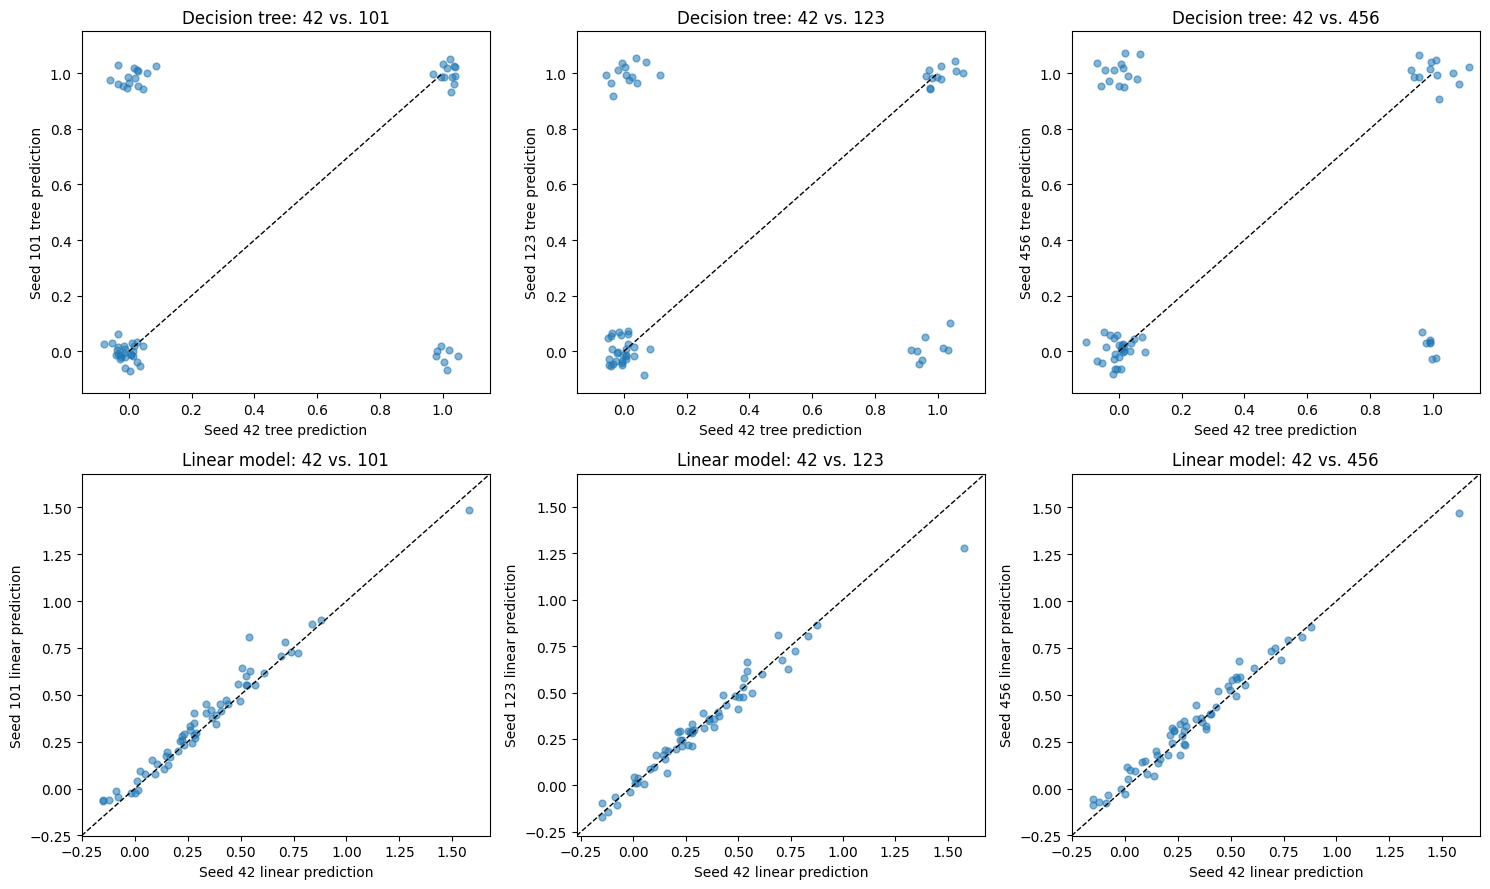

In [20]:
# Q4a: Scatterplots — baseline seed 42 on x-axis, other seeds on y-axis.
fig, axes = plt.subplots(2, len(results) - 1, figsize=(15, 9))
rng = np.random.default_rng(42)

for j, item in enumerate(results[1:]):
    tree_alt = item["tree"].predict(X_reference_test)
    linear_alt = item["linear model"].predict(X_reference_test)
    axes[0, j].scatter(
        baseline_tree + rng.normal(0, 0.04, len(baseline_tree)),
        tree_alt + rng.normal(0, 0.04, len(tree_alt)),
        alpha=0.55, s=24
    )
    axes[0, j].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[0, j].set(xlim=(-0.15, 1.15), ylim=(-0.15, 1.15),
                   xlabel="Seed 42 tree prediction",
                   ylabel=f"Seed {item['seed']} tree prediction",
                   title=f"Decision tree: 42 vs. {item['seed']}")

    axes[1, j].scatter(baseline_linear, linear_alt, alpha=0.55, s=24)
    limits = [min(baseline_linear.min(), linear_alt.min()) - 0.1,
              max(baseline_linear.max(), linear_alt.max()) + 0.1]
    axes[1, j].plot(limits, limits, "k--", linewidth=1)
    axes[1, j].set(xlim=limits, ylim=limits,
                   xlabel="Seed 42 linear prediction",
                   ylabel=f"Seed {item['seed']} linear prediction",
                   title=f"Linear model: 42 vs. {item['seed']}")

plt.tight_layout()
plt.savefig("trees_model_stability_Q4_scatterplots.png", dpi=170, bbox_inches="tight")
plt.show()


### Q4b and Q4c — Interpretation

When I compared the models on the same 60 observations, the **tree predictions were not highly correlated** across seeds: their correlations with the seed-42 predictions ranged from about **0.248 to 0.297**. They agreed on only about **63%–67%** of the classifications. The regression intercepts were around **0.32–0.37**, slopes were around **0.26–0.31**, and R² values were only **0.062–0.088**. Those values are not especially close to the ideal intercept of 0, slope of 1, and R² of 1.

The **linear predictions were much more consistent**. Their correlations were around **0.980–0.985**, with intercepts around **0.025–0.042**, slopes around **0.909–0.970**, and R² values around **0.961–0.969**. The linear scatterplots cluster close to the 45-degree line, while the tree plots show more disagreement.

## Q5 — Coefficients and tree structures

In [21]:
# Q5: Compare linear coefficients and decision-tree structures across seeds.
coefficient_table = pd.DataFrame(
    {f"Seed {item['seed']}": item["linear model"].coef_
     for item in results},
    index=X.columns
)
print("Linear model coefficients (feature units vary):")
display(coefficient_table.round(6))

structure = pd.DataFrame([
    {
        "Seed": item["seed"],
        "Depth": item["tree"].get_depth(),
        "Leaves": item["tree"].get_n_leaves(),
        "Root split feature": X.columns[item["tree"].tree_.feature[0]],
    }
    for item in results
])
print("Decision tree structures:")
display(structure)

Linear model coefficients (feature units vary):


,Seed 42,Seed 101,Seed 123,Seed 456
age,0.006293,0.007078,0.005747,0.005876
anaemia,-0.014492,0.002584,-0.013821,0.023301
creatinine_phosphokinase,0.000017,0.000043,0.000019,0.000025
diabetes,0.037456,0.010693,0.001406,0.052361
ejection_fraction,-0.009022,-0.010645,-0.009289,-0.011409
high_blood_pressure,-0.021997,0.012430,-0.000320,-0.010240
platelets,-0.000000,0.000000,-0.000000,0.000000
serum_creatinine,0.107125,0.082581,0.069897,0.090975
serum_sodium,-0.005685,-0.003069,-0.008791,-0.005918
sex,-0.087143,-0.074927,-0.049542,-0.055527


Decision tree structures:


,Seed,Depth,Leaves,Root split feature
0,42,9,31,time
1,101,11,38,time
2,123,8,35,time
3,456,11,43,time


### Q5 — Interpretation

The linear models have fairly similar overall predictions and several important coefficients keep the same sign across seeds. For example, `age` and `serum_creatinine` stay positive, while `ejection_fraction` and `time` stay negative. Some smaller coefficients, including `anaemia`, `high_blood_pressure`, and `smoking`, do change signs, so the coefficients are **not identical or completely stable**. Overall, though, the linear model predictions are very similar.

The trees change more. Their depths range from **8 to 11**, and their leaf counts range from **31 to 43**. All four trees split first on `time`, but their later branches and classifications differ. Between one-third and slightly more than one-third of the reference observations receive a different classification from the alternative trees compared with seed 42. This supports the idea that an unrestricted decision tree is sensitive to changes in the training data.


## Q6 — Conclusion

### Q6 — True or false?

**For this dataset and these models, I would say false overall.** The trees can look different across the training splits, and in this case their predictions also change by a noticeable amount. The tree prediction correlations with the baseline are only around **0.25–0.30**, and about **33%–37%** of their classifications disagree with the baseline. In contrast, the linear models have very similar predictions, with correlations above **0.98**, even though some individual coefficients change. So the statement may be true in other situations, but it is not well supported for the trees in this experiment. The results show why it is important to check predictions directly instead of judging stability only from what a model looks like.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 9cb4c64
- **AI tool and model used:** ChatGPT, GPT-5.6 Sol

### *Prompts used

1. Review my completed Phase 1 for the tree stability lab and identify any mistakes or improvements for Questions 1-6.
2. Check whether my data cleaning for the heart failure dataset is correct and whether the notebook will run in Colab.
3. Check my train-test split, decision tree, and linear regression code and make sure I am properly evaluating both models on the test data.
4. Review my comparison across different random seeds and help me better explain how the tree structures and linear regression coefficients change.
5. Check my Question 4 prediction comparisons, correlations, and regressions and help me interpret whether the models are stable.
6. Help me improve my explanations for Questions 5 and 6 based on the actual prediction and model stability results.

### *AI-proposed changes


1. Replace the computer-specific CSV path with a path that works from the repository's data folder.
2. Change the cleaning code so that dropna() actually modifies the dataframe instead of calling it without saving the result.
3. Add explicit test-set performance measures for Question 2 so the decision tree and linear model are actually evaluated, rather than only generating predictions.
4. Make the Question 3 comparison clearer by comparing the linear regression coefficients and basic tree structure across the different random seeds.
5. Make sure all models in Question 4 are compared using the same test observations before comparing their predictions.
6. Use the numerical results from Question 4 to make the stability conclusions more specific instead of relying only on how the models look.
7. Clarify Question 5 by separating stability of the model itself from stability of its predictions.
8. Make the Question 6 conclusion specific to this dataset and these models instead of treating the result as a universal statement about all decision trees and linear models.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The original path depended on another person's Downloads folder, so it did not work in Colab. I verified the dataset was in the repository and changed the path to use the data folder. |
| 2 | Accept | The original `heart.dropna()` call did not save the cleaned dataframe. I changed it to assign the cleaned result back to `heart` and checked for remaining missing values. |
| 3 | Accept | Question 2 asks us to evaluate performance on the test set, so reporting test metrics makes the answer more complete. |
| 4 | Accept | Looking at coefficients along with tree depth, leaves, and splits makes it easier to compare how the fitted models change across random seeds. |
| 5 | Accept | The predictions need to refer to the same observations for the scatterplots, correlations, and regression comparisons to be meaningful. |
| 6 | Accept | The numerical results support a much clearer comparison between the tree and linear models than simply saying the models look different. |
| 7 | Accept | A model can change internally while still making similar predictions, so it was important to discuss coefficient/structure stability separately from prediction stability. |
| 8 | Accept | The conclusions only come from this dataset and the random seeds tested, so I changed the wording to avoid overgeneralizing. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [24]:
# Your Phase 2 solution to the problem goes here.

import pandas as pd
import numpy as np

heart = pd.read_csv(
    "data/heart_failure/heart_failure_clinical_records_dataset.csv"
)

heart = heart.dropna().copy()
heart["age"] = np.floor(heart["age"]).astype(int)

print("Shape:", heart.shape)
print("Missing values:", heart.isna().sum().sum())

heart.head()

Shape: (299, 13)
Missing values: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

X = heart.drop(columns="DEATH_EVENT")
y = heart["DEATH_EVENT"]

seed = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=seed
)

tree = DecisionTreeClassifier(random_state=seed)
tree.fit(X_train, y_train)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

tree_predictions = tree.predict(X_test)
linear_predictions = linear_model.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Seed:", seed)
print("Tree test accuracy:", tree_accuracy)
print("Linear test RMSE:", linear_rmse)
print("Linear test R²:", linear_r2)

Seed: 42
Tree test accuracy: 0.6333333333333333
Linear test RMSE: 0.422694774797225
Linear test R²: 0.2648969811346785


The decision tree produces categorical outcomes with predictions that change substantially across the different seeds. This shows that changing the training sample can change how the tree classifies observations.

The linear model produce continuous predictions that also change across seeds.

In [27]:
seeds = [42, 101, 123, 456]

results = []

for seed in seeds:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed
    )

    tree = DecisionTreeClassifier(random_state=seed)
    tree.fit(X_train, y_train)

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    tree_predictions = tree.predict(X_test)
    linear_predictions = linear_model.predict(X_test)

    tree_accuracy = accuracy_score(
        y_test,
        tree_predictions
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            linear_predictions
        )
    )

    linear_r2 = r2_score(
        y_test,
        linear_predictions
    )

    results.append({
        "seed": seed,
        "tree": tree,
        "linear model": linear_model,
        "tree prediction": tree_predictions,
        "linear prediction": linear_predictions,
        "tree accuracy": tree_accuracy,
        "linear RMSE": linear_rmse,
        "linear R2": linear_r2
    })

In [28]:
metrics_table = pd.DataFrame([
    {
        "Seed": item["seed"],
        "Tree test accuracy": item["tree accuracy"],
        "Linear test RMSE": item["linear RMSE"],
        "Linear test R2": item["linear R2"]
    }
    for item in results
])

metrics_table.round(3)

,Seed,Tree test accuracy,Linear test RMSE,Linear test R2
0,42,0.633,0.423,0.265
1,101,0.850,0.342,0.377
2,123,0.833,0.379,0.411
3,456,0.767,0.343,0.457


In [29]:
tree_structure = pd.DataFrame([
    {
        "Seed": item["seed"],
        "Depth": item["tree"].get_depth(),
        "Leaves": item["tree"].get_n_leaves(),
        "Root split feature":
            X.columns[
                item["tree"].tree_.feature[0]
            ]
    }

    for item in results
])

tree_structure

,Seed,Depth,Leaves,Root split feature
0,42,9,31,time
1,101,11,38,time
2,123,8,35,time
3,456,11,43,time


In [30]:
reference_seed = 42

_, X_reference_test, _, y_reference_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=reference_seed
)

baseline_tree = results[0]["tree"].predict(
    X_reference_test
)

baseline_linear = results[0]["linear model"].predict(
    X_reference_test
)

In [31]:
comparison_rows = []

for item in results[1:]:

    # TREE
    alternate_tree = item["tree"].predict(
        X_reference_test
    )

    tree_corr = np.corrcoef(
        baseline_tree,
        alternate_tree
    )[0, 1]

    tree_reg = LinearRegression()

    tree_reg.fit(
        baseline_tree.reshape(-1, 1),
        alternate_tree
    )

    comparison_rows.append({
        "Seed": item["seed"],
        "Model": "Decision tree",
        "Correlation": tree_corr,
        "Intercept": tree_reg.intercept_,
        "Slope": tree_reg.coef_[0],
        "R2": tree_reg.score(
            baseline_tree.reshape(-1, 1),
            alternate_tree
        ),
        "Same prediction (%)":
            100 * np.mean(
                baseline_tree == alternate_tree
            )
    })


    # LINEAR MODEL
    alternate_linear = item["linear model"].predict(
        X_reference_test
    )

    linear_corr = np.corrcoef(
        baseline_linear,
        alternate_linear
    )[0, 1]

    linear_reg = LinearRegression()

    linear_reg.fit(
        baseline_linear.reshape(-1, 1),
        alternate_linear
    )

    comparison_rows.append({
        "Seed": item["seed"],
        "Model": "Linear model",
        "Correlation": linear_corr,
        "Intercept": linear_reg.intercept_,
        "Slope": linear_reg.coef_[0],
        "R2": linear_reg.score(
            baseline_linear.reshape(-1, 1),
            alternate_linear
        ),
        "Same prediction (%)": np.nan
    })


comparison = pd.DataFrame(
    comparison_rows
)

comparison.round(3)

,Seed,Model,Correlation,Intercept,Slope,R2,Same prediction (%)
0,101,Decision tree,0.248,0.366,0.266,0.062,63.333
1,101,Linear model,0.983,0.042,0.970,0.967,NaN
2,123,Decision tree,0.249,0.317,0.262,0.062,65.000
3,123,Linear model,0.980,0.025,0.909,0.961,NaN
4,456,Decision tree,0.297,0.317,0.315,0.088,66.667
5,456,Linear model,0.985,0.041,0.946,0.969,NaN


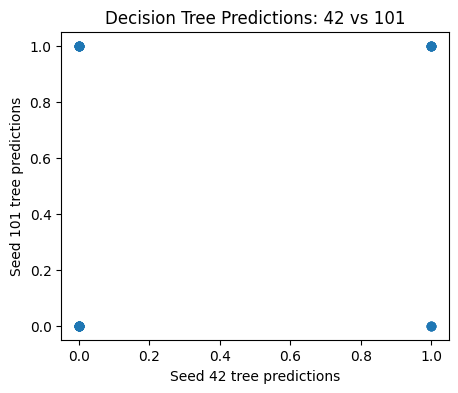

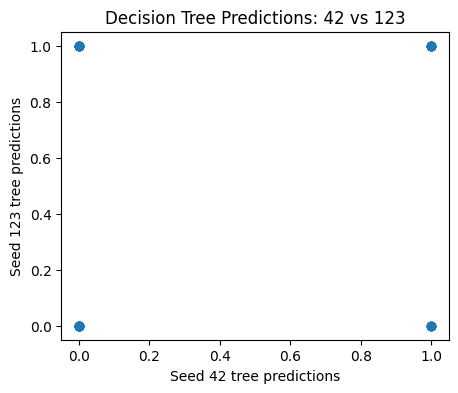

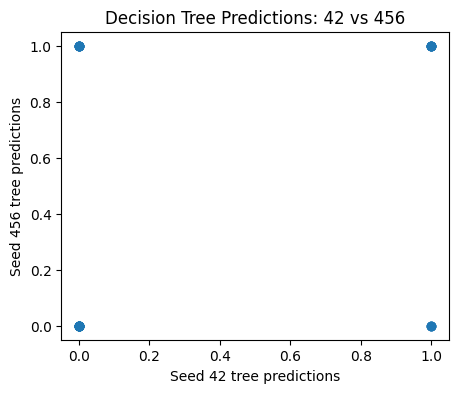

In [32]:
import matplotlib.pyplot as plt

for item in results[1:]:

    alternate_tree = item["tree"].predict(
        X_reference_test
    )

    plt.figure(figsize=(5, 4))

    plt.scatter(
        baseline_tree,
        alternate_tree,
        alpha=0.6
    )

    plt.xlabel("Seed 42 tree predictions")
    plt.ylabel(
        f"Seed {item['seed']} tree predictions"
    )

    plt.title(
        f"Decision Tree Predictions: "
        f"42 vs {item['seed']}"
    )

    plt.show()

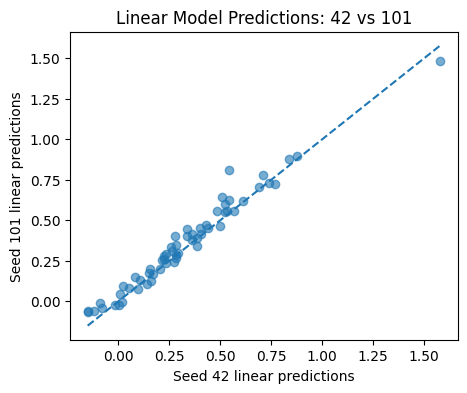

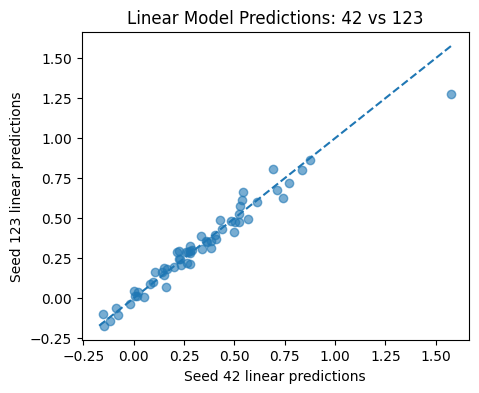

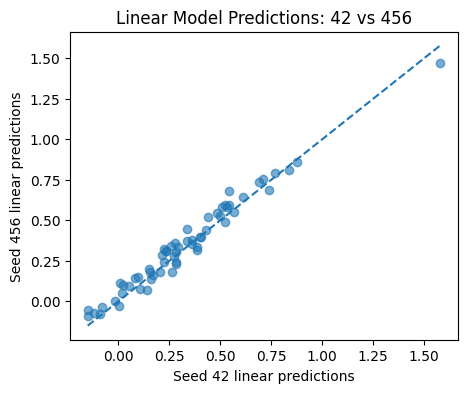

In [33]:
for item in results[1:]:

    alternate_linear = item[
        "linear model"
    ].predict(
        X_reference_test
    )

    plt.figure(figsize=(5, 4))

    plt.scatter(
        baseline_linear,
        alternate_linear,
        alpha=0.6
    )

    min_val = min(
        baseline_linear.min(),
        alternate_linear.min()
    )

    max_val = max(
        baseline_linear.max(),
        alternate_linear.max()
    )

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    plt.xlabel(
        "Seed 42 linear predictions"
    )

    plt.ylabel(
        f"Seed {item['seed']} "
        "linear predictions"
    )

    plt.title(
        f"Linear Model Predictions: "
        f"42 vs {item['seed']}"
    )

    plt.show()

### Q4b and Q4c — Interpretation

When I compared the models on the same 60 observations, the **tree predictions were not highly correlated** across seeds: their correlations with the seed-42 predictions ranged from about **0.248 to 0.297**. They agreed on only about **63%–67%** of the classifications. The regression intercepts were around **0.32–0.37**, slopes were around **0.26–0.31**, and R² values were only **0.062–0.088**. Those values are not especially close to the ideal intercept of 0, slope of 1, and R² of 1.

The **linear predictions were much more consistent**. Their correlations were around **0.980–0.985**, with intercepts around **0.025–0.042**, slopes around **0.909–0.970**, and R² values around **0.961–0.969**. The linear scatterplots cluster close to the 45-degree line, while the tree plots show more disagreement.

In [35]:
print("Linear model coefficients:")
display(
    coefficient_table.round(6)
)

print("Decision tree structures:")
display(
    tree_structure
)

print("Prediction comparisons:")
display(
    comparison.round(3)
)

Linear model coefficients:


,Seed 42,Seed 101,Seed 123,Seed 456
age,0.006293,0.007078,0.005747,0.005876
anaemia,-0.014492,0.002584,-0.013821,0.023301
creatinine_phosphokinase,0.000017,0.000043,0.000019,0.000025
diabetes,0.037456,0.010693,0.001406,0.052361
ejection_fraction,-0.009022,-0.010645,-0.009289,-0.011409
high_blood_pressure,-0.021997,0.012430,-0.000320,-0.010240
platelets,-0.000000,0.000000,-0.000000,0.000000
serum_creatinine,0.107125,0.082581,0.069897,0.090975
serum_sodium,-0.005685,-0.003069,-0.008791,-0.005918
sex,-0.087143,-0.074927,-0.049542,-0.055527


Decision tree structures:


,Seed,Depth,Leaves,Root split feature
0,42,9,31,time
1,101,11,38,time
2,123,8,35,time
3,456,11,43,time


Prediction comparisons:


,Seed,Model,Correlation,Intercept,Slope,R2,Same prediction (%)
0,101,Decision tree,0.248,0.366,0.266,0.062,63.333
1,101,Linear model,0.983,0.042,0.970,0.967,NaN
2,123,Decision tree,0.249,0.317,0.262,0.062,65.000
3,123,Linear model,0.980,0.025,0.909,0.961,NaN
4,456,Decision tree,0.297,0.317,0.315,0.088,66.667
5,456,Linear model,0.985,0.041,0.946,0.969,NaN


### Q5 — Interpretation

The linear models have fairly similar overall predictions and several important coefficients keep the same sign across seeds. For example, `age` and `serum_creatinine` stay positive, while `ejection_fraction` and `time` stay negative. Some smaller coefficients, including `anaemia`, `high_blood_pressure`, and `smoking`, do change signs, so the coefficients are **not identical or completely stable**. Overall, though, the linear model predictions are very similar.

The trees change more. Their depths range from **8 to 11**, and their leaf counts range from **31 to 43**. All four trees split first on `time`, but their later branches and classifications differ. Between one-third and slightly more than one-third of the reference observations receive a different classification from the alternative trees compared with seed 42. This supports the idea that an unrestricted decision tree is sensitive to changes in the training data.


### Q6 — True or false?

**For this dataset and these models, I would say false overall.** The trees can look different across the training splits, and in this case their predictions also change by a noticeable amount. The tree prediction correlations with the baseline are only around **0.25–0.30**, and about **33%–37%** of their classifications disagree with the baseline. In contrast, the linear models have very similar predictions, with correlations above **0.98**, even though some individual coefficients change. So the statement may be true in other situations, but it is not well supported for the trees in this experiment. The results show why it is important to check predictions directly instead of judging stability only from what a model looks like.


### *Reflection on AI assistance
In your own words without generative AI.

In Phase 2, I mostly improved the code's reproducibility and the clarity of the model comparisons. Fixing the data-loading procedure to enable the notebook to function in Colab rather than depending on a file path from a single computer was one significant modification. Additionally, I introduced more precise evaluation criteria for the decision tree and linear regression models and ensured that the cleaning step truly eliminated missing values. Although the AI was useful in structuring the study and highlighting areas where the original code could be improved, I still needed to make sure the recommendations aligned with the task. For instance, since the outcome variable is binary, logistic regression might have made sense; but, since the assignment explicitly requested a linear model, I chose to stick with linear regression. I ran the code again and compared the results amongst the several random seeds to confirm the changes. The decision trees were significantly less consistent across splits than the linear models, which yielded relatively comparable predictions with correlations around 0.98. To ensure that the written conclusions matched the actual outputs, I also examined the tree structures, coefficients, scatterplots, correlations, and regression findings. The fact that these findings are based on a short dataset and only a few train-test splits is one last drawback. As a result, the precise stability results may vary depending on other seeds or modeling decisions.